Challenge 6

Andrea P. Gómez Jaime

In [56]:
#import warnings
#warnings.filterwarnings("ignore")


In [57]:
import numpy as np
import matplotlib.pyplot as plt
from nilearn import datasets
from nilearn.maskers import NiftiLabelsMasker
from nilearn.image import index_img
import nibabel as nib
from sklearn.linear_model import LogisticRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import r2_score
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, cross_validate, LeaveOneOut, ShuffleSplit, train_test_split, StratifiedShuffleSplit, GridSearchCV, cross_val_predict

In [58]:
brain_data = datasets.fetch_oasis_vbm(n_subjects=100)
yeo = datasets.fetch_atlas_schaefer_2018(n_rois=200) 
print('%i regions found in this atlas' % (len(np.unique( nib.load(yeo.maps).get_fdata().ravel())) - 1))
masker = NiftiLabelsMasker(labels_img=yeo.maps, standardize=True,
memory='nilearn_cache')
input_variables = masker.fit_transform(brain_data.gray_matter_maps)
output_variable = np.array(brain_data.ext_vars.mf == 'F', dtype=int) # gives 1 for females and 0 for male

[fetch_oasis_vbm] Dataset directory found: C:\Users\Asus\nilearn_data\oasis1
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
200 regions found in this atlas


Part A

Task 1

In [59]:
def get_features(labels_img):
    masker = NiftiLabelsMasker(labels_img=labels_img, standardize="zscore_sample",
                               memory='nilearn_cache')
    return masker.fit_transform(brain_data.gray_matter_maps)

def split(X, y, n_train=80):
    return X[:n_train], X[n_train:], y[:n_train], y[n_train:]

In [60]:
def run_atlas_sweep(atlas_items, get_labels_img, y=output_variable):
    accuracies_logreg = []
    for item in atlas_items:
        X = get_features(get_labels_img(item))
        #X_train, X_test, y_train, y_test = split(X, y)

        logreg = LogisticRegression(C=1.0, penalty='l2')
        cross_val_scores = cross_val_score(logreg, X, y, cv=5)
        #logreg.fit(X_train, y_train)
        mean_cv_score = np.mean(cross_val_scores)

        # test-set accuracy as a percentage (XX.YY)
        accuracies_logreg.append(round(100 * mean_cv_score, 2))
    return accuracies_logreg

In [61]:
res = np.arange(100, 1001, 100)
accuracies_logreg = run_atlas_sweep(
    res, lambda r: datasets.fetch_atlas_schaefer_2018(n_rois=r).maps)

for r, a_lr in zip(res, accuracies_logreg):
    print(f"{r:>5} ROIs | LogReg: {a_lr:.2f}%")

[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
  100 ROIs | LogReg: 70.00%
  200 ROIs | LogReg: 71.00%
  30

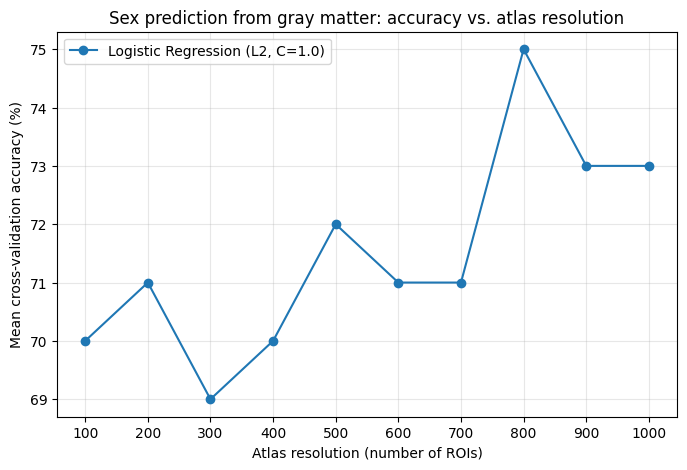

In [62]:
plt.figure(figsize=(8, 5))
plt.plot(res, accuracies_logreg, marker='o', color='tab:blue', label='Logistic Regression (L2, C=1.0)')
plt.xlabel('Atlas resolution (number of ROIs)')
plt.ylabel('Mean cross-validation accuracy (%)')
plt.title('Sex prediction from gray matter: accuracy vs. atlas resolution')
plt.xticks(res)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Task 2

In [63]:
def run_atlas_sweep_loo(atlas_items, get_labels_img, y=output_variable):
    accuracies_logreg = []
    for item in atlas_items:
        X = get_features(get_labels_img(item))
        #X_train, X_test, y_train, y_test = split(X, y)

        logreg = LogisticRegression(C=1.0, penalty='l2')
        cross_val_scores = cross_val_score(logreg, X, y, cv=LeaveOneOut())
        #logreg.fit(X_train, y_train)
        mean_cv_score = np.mean(cross_val_scores)

        # test-set accuracy as a percentage (XX.YY)
        accuracies_logreg.append(round(100 * mean_cv_score, 2))
    return accuracies_logreg

In [64]:
res = np.arange(100, 1001, 100)
accuracies_logreg_loo = run_atlas_sweep_loo(
    res, lambda r: datasets.fetch_atlas_schaefer_2018(n_rois=r).maps)

for r, a_lr in zip(res, accuracies_logreg_loo):
    print(f"{r:>5} ROIs | LogReg: {a_lr:.2f}%")

[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
  100 ROIs | LogReg: 68.00%
  200 ROIs | LogReg: 72.00%
  30

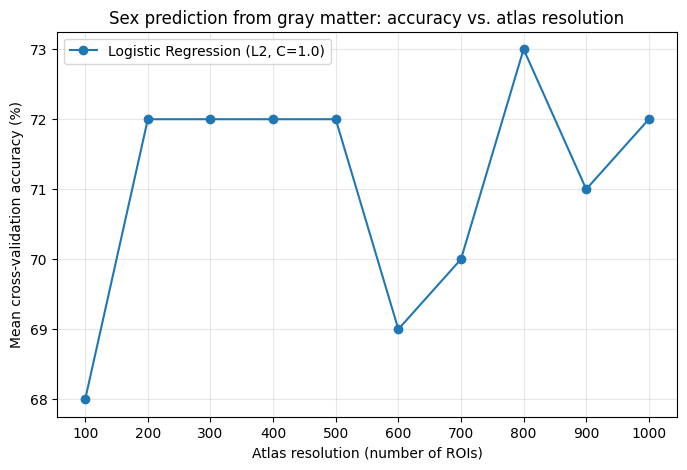

In [65]:
plt.figure(figsize=(8, 5))
plt.plot(res, accuracies_logreg_loo, marker='o', color='tab:blue', label='Logistic Regression (L2, C=1.0)')
plt.xlabel('Atlas resolution (number of ROIs)')
plt.ylabel('Mean cross-validation accuracy (%)')
plt.title('Sex prediction from gray matter: accuracy vs. atlas resolution')
plt.xticks(res)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Task 3

In [66]:
def run_atlas_sweep_MC(atlas_items, get_labels_img, y=output_variable):
    accuracies_logreg = []
    for item in atlas_items:
        X = get_features(get_labels_img(item))
        #X_train, X_test, y_train, y_test = split(X, y)

        logreg = LogisticRegression(C=1.0, penalty='l2')
        
        cv = ShuffleSplit(n_splits=50, test_size=0.2, random_state=0)
        cross_val_scores = cross_val_score(logreg, X, y, cv=cv)
        #logreg.fit(X_train, y_train)
        mean_cv_score = np.mean(cross_val_scores)

        # test-set accuracy as a percentage (XX.YY)
        accuracies_logreg.append(round(100 * mean_cv_score, 2))
    return accuracies_logreg

In [67]:
res = np.arange(100, 1001, 100)
accuracies_logreg_MC = run_atlas_sweep_MC(
    res, lambda r: datasets.fetch_atlas_schaefer_2018(n_rois=r).maps)

for r, a_lr in zip(res, accuracies_logreg_MC):
    print(f"{r:>5} ROIs | LogReg: {a_lr:.2f}%")

[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
  100 ROIs | LogReg: 66.20%
  200 ROIs | LogReg: 68.60%
  30

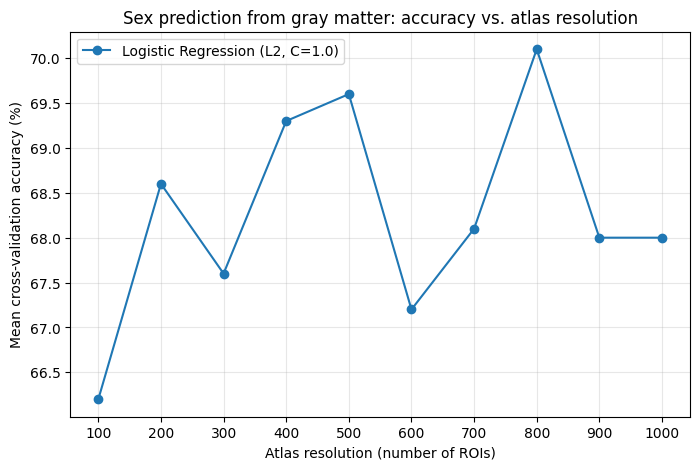

In [68]:
plt.figure(figsize=(8, 5))
plt.plot(res, accuracies_logreg_MC, marker='o', color='tab:blue', label='Logistic Regression (L2, C=1.0)')
plt.xlabel('Atlas resolution (number of ROIs)')
plt.ylabel('Mean cross-validation accuracy (%)')
plt.title('Sex prediction from gray matter: accuracy vs. atlas resolution')
plt.xticks(res)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Task 4

In [69]:
def run_atlas_sweep_MCS(atlas_items, get_labels_img, y=output_variable):
    accuracies_logreg = []
    for item in atlas_items:
        X = get_features(get_labels_img(item))
        #X_train, X_test, y_train, y_test = split(X, y)

        logreg = LogisticRegression(C=1.0, penalty='l2')
        
        cv = StratifiedShuffleSplit(n_splits=50, test_size=0.2, random_state=0)
        cross_val_scores = cross_val_score(logreg, X, y, cv=cv)
        #logreg.fit(X_train, y_train)
        mean_cv_score = np.mean(cross_val_scores)

        # test-set accuracy as a percentage (XX.YY)
        accuracies_logreg.append(round(100 * mean_cv_score, 2))
    return accuracies_logreg

In [70]:
res = np.arange(100, 1001, 100)
accuracies_logreg_MCS = run_atlas_sweep_MCS(
    res, lambda r: datasets.fetch_atlas_schaefer_2018(n_rois=r).maps)

for r, a_lr in zip(res, accuracies_logreg_MCS):
    print(f"{r:>5} ROIs | LogReg: {a_lr:.2f}%")

[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
  100 ROIs | LogReg: 70.80%
  200 ROIs | LogReg: 71.50%
  30

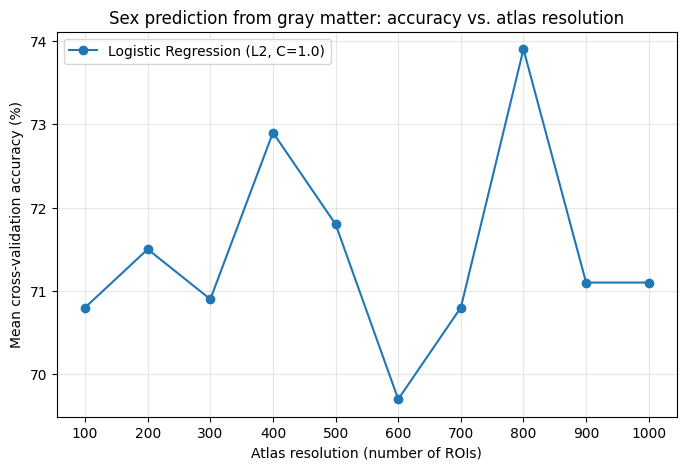

In [71]:
plt.figure(figsize=(8, 5))
plt.plot(res, accuracies_logreg_MCS, marker='o', color='tab:blue', label='Logistic Regression (L2, C=1.0)')
plt.xlabel('Atlas resolution (number of ROIs)')
plt.ylabel('Mean cross-validation accuracy (%)')
plt.title('Sex prediction from gray matter: accuracy vs. atlas resolution')
plt.xticks(res)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Task 5

In [72]:
def run_atlas_sweep_nested(atlas_items, get_labels_img, y=output_variable):
    accuracies_logreg = []
    Cs = np.logspace(-4, 4, 10)

    for item in atlas_items:
        X = get_features(get_labels_img(item))
        #X_train, X_test, y_train, y_test = split(X, y)

        logreg = LogisticRegression(C=1.0, penalty='l2')
        inner_cv = GridSearchCV(logreg, param_grid={'C': Cs}, cv=5)       # inner loop
        outer_scores = cross_val_score(inner_cv, X, y, cv=10)             # outer loop
        #logreg.fit(X_train, y_train)
        mean_cv_score = np.mean(outer_scores)

        # test-set accuracy as a percentage (XX.YY)
        accuracies_logreg.append(round(100 * mean_cv_score, 2))
    return accuracies_logreg

In [73]:
res = np.arange(100, 1001, 100)
accuracies_logreg_n = run_atlas_sweep_nested(
    res, lambda r: datasets.fetch_atlas_schaefer_2018(n_rois=r).maps)

for r, a_lr in zip(res, accuracies_logreg_n):
    print(f"{r:>5} ROIs | LogReg: {a_lr:.2f}%")

[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
  100 ROIs | LogReg: 70.00%
  200 ROIs | LogReg: 64.00%
  30

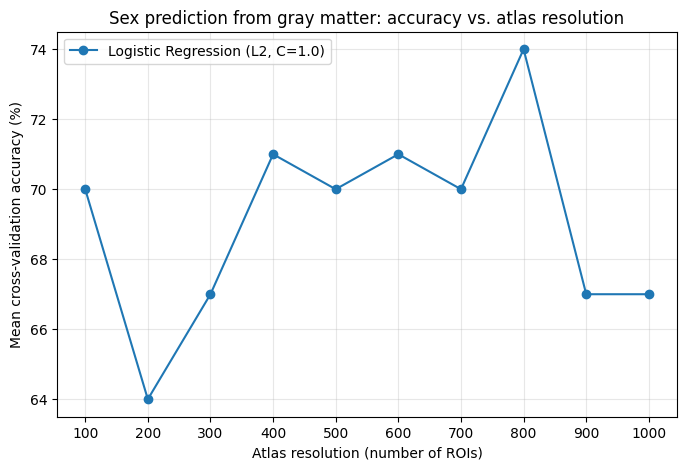

In [74]:
plt.figure(figsize=(8, 5))
plt.plot(res, accuracies_logreg_n, marker='o', color='tab:blue', label='Logistic Regression (L2, C=1.0)')
plt.xlabel('Atlas resolution (number of ROIs)')
plt.ylabel('Mean cross-validation accuracy (%)')
plt.title('Sex prediction from gray matter: accuracy vs. atlas resolution')
plt.xticks(res)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Part B

In [75]:
brain_data = datasets.fetch_oasis_vbm(n_subjects=100)
crad = {'scorr_mean': 'craddock_2011_parcellations/scorr05_mean_all.nii.gz'}
atlas_nii = index_img(crad['scorr_mean'], 42)
print('%i regions found in this atlas' % (len(np.unique(atlas_nii.get_fdata().ravel())) - 1))
masker = NiftiLabelsMasker(labels_img= atlas_nii, standardize=True)
input_variables = masker.fit_transform(brain_data.gray_matter_maps)
output_variable = StandardScaler().fit_transform(brain_data.ext_vars.age.to_numpy()[:, None])[:,
0] # gives subject age on standard units after z-scoring

[fetch_oasis_vbm] Dataset directory found: C:\Users\Asus\nilearn_data\oasis1
788 regions found in this atlas


In [76]:
n_resolutions = nib.load(crad['scorr_mean']).shape[-1]  # should be 43
print(f"Number of resolutions in the Craddock atlas: {n_resolutions}")
craddock_indices = np.arange(n_resolutions)

def get_craddock_labels_img(idx):
    return index_img(crad['scorr_mean'], idx)


Number of resolutions in the Craddock atlas: 43


Task 6

In [77]:
def run_atlas_sweep_ridge(atlas_items, get_labels_img, y=output_variable):
    accuracies_logreg = []
    for item in atlas_items:
        X = get_features(get_labels_img(item))
        #X_train, X_test, y_train, y_test = split(X, y)

        ridge = Ridge()
        cross_val_scores = cross_val_score(ridge, X, y, cv=5, scoring='r2')
        mean_r2 = np.mean(cross_val_scores)

        # test-set accuracy as a percentage (XX.YY)
        accuracies_logreg.append(round(100 * mean_r2, 2))
    return accuracies_logreg

In [78]:
accuracies_ridge = run_atlas_sweep_ridge(
    craddock_indices, get_craddock_labels_img)

for idx, a_r in zip(craddock_indices, accuracies_ridge):
    print(f"Craddock idx {idx:>3} | Ridge: {a_r:.2f}%")


Craddock idx   0 | Ridge: -45.77%
Craddock idx   1 | Ridge: -35.71%
Craddock idx   2 | Ridge: 0.16%
Craddock idx   3 | Ridge: -24.63%
Craddock idx   4 | Ridge: -17.37%
Craddock idx   5 | Ridge: 40.17%
Craddock idx   6 | Ridge: 15.77%
Craddock idx   7 | Ridge: 9.32%
Craddock idx   8 | Ridge: 45.19%
Craddock idx   9 | Ridge: 26.08%
Craddock idx  10 | Ridge: 7.37%
Craddock idx  11 | Ridge: 11.19%
Craddock idx  12 | Ridge: -17.63%
Craddock idx  13 | Ridge: -6.76%
Craddock idx  14 | Ridge: -0.13%
Craddock idx  15 | Ridge: 27.90%
Craddock idx  16 | Ridge: 27.39%
Craddock idx  17 | Ridge: 20.78%
Craddock idx  18 | Ridge: 38.12%
Craddock idx  19 | Ridge: 22.19%
Craddock idx  20 | Ridge: 40.24%
Craddock idx  21 | Ridge: 12.10%
Craddock idx  22 | Ridge: 40.85%
Craddock idx  23 | Ridge: 38.57%
Craddock idx  24 | Ridge: 39.74%
Craddock idx  25 | Ridge: 45.47%
Craddock idx  26 | Ridge: 48.26%
Craddock idx  27 | Ridge: 46.12%
Craddock idx  28 | Ridge: 47.81%
Craddock idx  29 | Ridge: 50.63%
Craddock

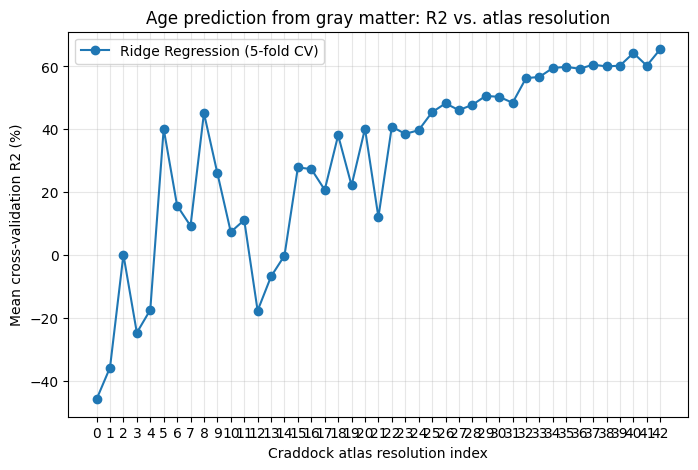

In [79]:
plt.figure(figsize=(8, 5))
plt.plot(craddock_indices, accuracies_ridge, marker='o', color='tab:blue', label='Ridge Regression (5-fold CV)')
plt.xlabel('Craddock atlas resolution index')
plt.ylabel('Mean cross-validation R2 (%)')
plt.title('Age prediction from gray matter: R2 vs. atlas resolution')
plt.xticks(craddock_indices)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Task 7 

In [80]:
def run_atlas_sweep_loo_ridge(atlas_items, get_labels_img, y=output_variable):
    accuracies_logreg = []
    for item in atlas_items:
        X = get_features(get_labels_img(item))
        #X_train, X_test, y_train, y_test = split(X, y)

        ridge = Ridge()
        y_pred = cross_val_predict(ridge, X, y, cv=LeaveOneOut())
        #logreg.fit(X_train, y_train)
        mean_r2 = r2_score(y, y_pred)

        # test-set accuracy as a percentage (XX.YY)
        accuracies_logreg.append(round(100 * mean_r2, 2))
    return accuracies_logreg

In [81]:
accuracies_ridge_loo = run_atlas_sweep_loo_ridge(craddock_indices, get_craddock_labels_img)

for idx, a_r in zip(craddock_indices, accuracies_ridge_loo):
    print(f"Craddock idx {idx:>3} | Ridge: {a_r:.2f}%")

Craddock idx   0 | Ridge: -5.84%
Craddock idx   1 | Ridge: 6.01%
Craddock idx   2 | Ridge: 47.33%
Craddock idx   3 | Ridge: 23.30%
Craddock idx   4 | Ridge: 38.51%
Craddock idx   5 | Ridge: 44.62%
Craddock idx   6 | Ridge: 33.26%
Craddock idx   7 | Ridge: 25.16%
Craddock idx   8 | Ridge: 50.17%
Craddock idx   9 | Ridge: 32.68%
Craddock idx  10 | Ridge: 39.93%
Craddock idx  11 | Ridge: 22.33%
Craddock idx  12 | Ridge: 18.46%
Craddock idx  13 | Ridge: 44.22%
Craddock idx  14 | Ridge: 27.73%
Craddock idx  15 | Ridge: 50.57%
Craddock idx  16 | Ridge: 55.21%
Craddock idx  17 | Ridge: 32.49%
Craddock idx  18 | Ridge: 51.25%
Craddock idx  19 | Ridge: 23.47%
Craddock idx  20 | Ridge: 50.59%
Craddock idx  21 | Ridge: 40.99%
Craddock idx  22 | Ridge: 61.96%
Craddock idx  23 | Ridge: 47.83%
Craddock idx  24 | Ridge: 58.37%
Craddock idx  25 | Ridge: 63.90%
Craddock idx  26 | Ridge: 64.34%
Craddock idx  27 | Ridge: 64.10%
Craddock idx  28 | Ridge: 61.14%
Craddock idx  29 | Ridge: 65.38%
Craddock id

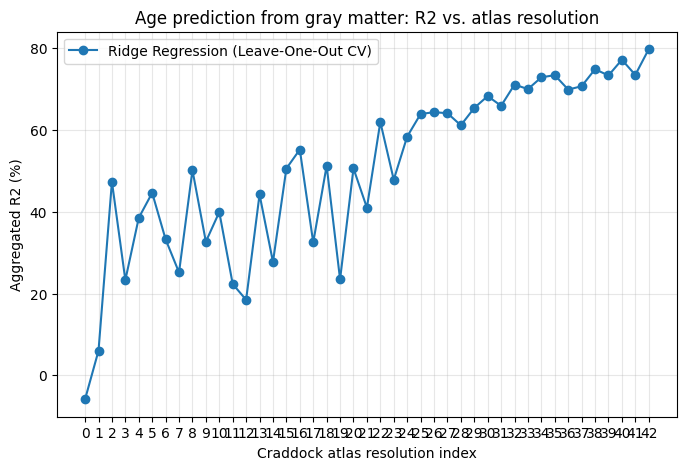

In [82]:
plt.figure(figsize=(8, 5))
plt.plot(craddock_indices, accuracies_ridge_loo, marker='o', color='tab:blue', label='Ridge Regression (Leave-One-Out CV)')
plt.xlabel('Craddock atlas resolution index')
plt.ylabel('Aggregated R2 (%)')
plt.title('Age prediction from gray matter: R2 vs. atlas resolution')
plt.xticks(craddock_indices)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Task 8

In [83]:
def run_atlas_sweep_MC_ridge(atlas_items, get_labels_img, y=output_variable):
    accuracies_logreg = []
    for item in atlas_items:
        X = get_features(get_labels_img(item))
        #X_train, X_test, y_train, y_test = split(X, y)

        ridge = Ridge()
        
        cv = ShuffleSplit(n_splits=50, test_size=0.2, random_state=0)
        cross_val_scores = cross_val_score(ridge, X, y, cv=cv, scoring='r2')
        #logreg.fit(X_train, y_train)
        mean_cv_score = np.mean(cross_val_scores)

        # test-set accuracy as a percentage (XX.YY)
        accuracies_logreg.append(round(100 * mean_cv_score, 2))
    return accuracies_logreg

In [84]:
accuracies_ridge_MC = run_atlas_sweep_MC_ridge(craddock_indices, get_craddock_labels_img)

for idx, a_r in zip(craddock_indices, accuracies_ridge_MC):
    print(f"Craddock idx {idx:>3} | Ridge: {a_r:.2f}%")


Craddock idx   0 | Ridge: -24.90%
Craddock idx   1 | Ridge: -14.49%
Craddock idx   2 | Ridge: 35.72%
Craddock idx   3 | Ridge: 5.91%
Craddock idx   4 | Ridge: 15.45%
Craddock idx   5 | Ridge: 31.57%
Craddock idx   6 | Ridge: 19.47%
Craddock idx   7 | Ridge: 16.89%
Craddock idx   8 | Ridge: 41.47%
Craddock idx   9 | Ridge: 29.80%
Craddock idx  10 | Ridge: 19.60%
Craddock idx  11 | Ridge: 17.24%
Craddock idx  12 | Ridge: 15.96%
Craddock idx  13 | Ridge: 27.94%
Craddock idx  14 | Ridge: 23.94%
Craddock idx  15 | Ridge: 39.63%
Craddock idx  16 | Ridge: 41.76%
Craddock idx  17 | Ridge: 32.19%
Craddock idx  18 | Ridge: 47.87%
Craddock idx  19 | Ridge: 30.28%
Craddock idx  20 | Ridge: 45.13%
Craddock idx  21 | Ridge: 38.64%
Craddock idx  22 | Ridge: 54.23%
Craddock idx  23 | Ridge: 44.93%
Craddock idx  24 | Ridge: 55.55%
Craddock idx  25 | Ridge: 57.22%
Craddock idx  26 | Ridge: 55.63%
Craddock idx  27 | Ridge: 57.47%
Craddock idx  28 | Ridge: 56.65%
Craddock idx  29 | Ridge: 57.48%
Craddock 

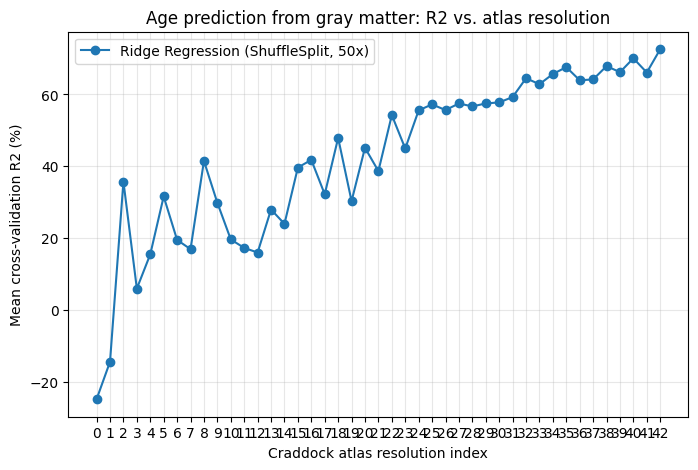

In [85]:
plt.figure(figsize=(8, 5))
plt.plot(craddock_indices, accuracies_ridge_MC, marker='o', color='tab:blue', label='Ridge Regression (ShuffleSplit, 50x)')
plt.xlabel('Craddock atlas resolution index')
plt.ylabel('Mean cross-validation R2 (%)')
plt.title('Age prediction from gray matter: R2 vs. atlas resolution')
plt.xticks(craddock_indices)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Task 9

In [86]:
def run_atlas_sweep_MCS_ridge(atlas_items, get_labels_img, y=output_variable):
    accuracies_logreg = []
    for item in atlas_items:
        X = get_features(get_labels_img(item))
        #X_train, X_test, y_train, y_test = split(X, y)

        age_groups = (y > np.median(y)).astype(int)    # binary split, just for stratification
        cv = StratifiedShuffleSplit(n_splits=50, test_size=0.2, random_state=0)

        r2_scores = []
        for train_idx, test_idx in cv.split(X, age_groups):
            ridge = Ridge()
            ridge.fit(X[train_idx], y[train_idx])
            y_pred = ridge.predict(X[test_idx])
            r2_scores.append(r2_score(y[test_idx], y_pred))
        mean_cv_score = np.mean(r2_scores)

        # test-set accuracy as a percentage (XX.YY)
        accuracies_logreg.append(round(100 * mean_cv_score, 2))
    return accuracies_logreg

In [87]:
accuracies_ridge_MCS = run_atlas_sweep_MCS_ridge(craddock_indices, get_craddock_labels_img)

for idx, a_r in zip(craddock_indices, accuracies_ridge_MCS):
    print(f"Craddock idx {idx:>3} | Ridge: {a_r:.2f}%")

Craddock idx   0 | Ridge: -11.21%
Craddock idx   1 | Ridge: -3.06%
Craddock idx   2 | Ridge: 37.32%
Craddock idx   3 | Ridge: 10.55%
Craddock idx   4 | Ridge: 21.02%
Craddock idx   5 | Ridge: 27.00%
Craddock idx   6 | Ridge: 19.65%
Craddock idx   7 | Ridge: 12.98%
Craddock idx   8 | Ridge: 39.50%
Craddock idx   9 | Ridge: 33.01%
Craddock idx  10 | Ridge: 24.24%
Craddock idx  11 | Ridge: 6.74%
Craddock idx  12 | Ridge: 18.02%
Craddock idx  13 | Ridge: 34.89%
Craddock idx  14 | Ridge: 28.38%
Craddock idx  15 | Ridge: 45.99%
Craddock idx  16 | Ridge: 47.52%
Craddock idx  17 | Ridge: 35.90%
Craddock idx  18 | Ridge: 51.79%
Craddock idx  19 | Ridge: 36.09%
Craddock idx  20 | Ridge: 50.95%
Craddock idx  21 | Ridge: 42.44%
Craddock idx  22 | Ridge: 56.92%
Craddock idx  23 | Ridge: 46.40%
Craddock idx  24 | Ridge: 57.92%
Craddock idx  25 | Ridge: 58.87%
Craddock idx  26 | Ridge: 59.05%
Craddock idx  27 | Ridge: 60.31%
Craddock idx  28 | Ridge: 58.74%
Craddock idx  29 | Ridge: 60.27%
Craddock i

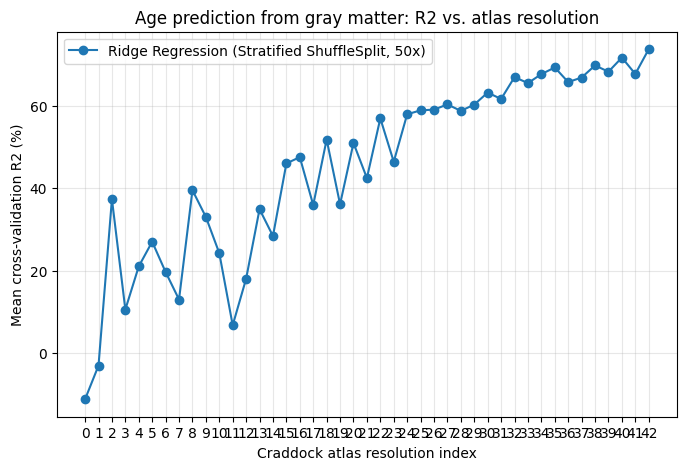

In [88]:
plt.figure(figsize=(8, 5))
plt.plot(craddock_indices, accuracies_ridge_MCS, marker='o', color='tab:blue', label='Ridge Regression (Stratified ShuffleSplit, 50x)')
plt.xlabel('Craddock atlas resolution index')
plt.ylabel('Mean cross-validation R2 (%)')
plt.title('Age prediction from gray matter: R2 vs. atlas resolution')
plt.xticks(craddock_indices)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Task 10

In [89]:
def run_atlas_sweep_nested_ridge(atlas_items, get_labels_img, y=output_variable):
    accuracies_logreg = []
    Cs = np.logspace(-4, 4, 10)

    for item in atlas_items:
        X = get_features(get_labels_img(item))
        #X_train, X_test, y_train, y_test = split(X, y)

        ridge = Ridge()
        inner_cv = GridSearchCV(ridge, param_grid={'alpha': Cs}, cv=5, scoring='r2')       # inner loop
        outer_scores = cross_val_score(inner_cv, X, y, cv=10, scoring='r2')             # outer loop
        #logreg.fit(X_train, y_train)
        mean_cv_score = np.mean(outer_scores)

        # test-set accuracy as a percentage (XX.YY)
        accuracies_logreg.append(round(100 * mean_cv_score, 2))
    return accuracies_logreg

In [90]:
accuracies_ridge_nested = run_atlas_sweep_nested_ridge(craddock_indices, get_craddock_labels_img)

for idx, a_r in zip(craddock_indices, accuracies_ridge_nested):
    print(f"Craddock idx {idx:>3} | Nested Ridge: {a_r:.2f}%")

Craddock idx   0 | Nested Ridge: -31.20%
Craddock idx   1 | Nested Ridge: -43.97%
Craddock idx   2 | Nested Ridge: 1.29%
Craddock idx   3 | Nested Ridge: -20.64%
Craddock idx   4 | Nested Ridge: -26.72%
Craddock idx   5 | Nested Ridge: -13.95%
Craddock idx   6 | Nested Ridge: 2.84%
Craddock idx   7 | Nested Ridge: 16.65%
Craddock idx   8 | Nested Ridge: 12.63%
Craddock idx   9 | Nested Ridge: 18.92%
Craddock idx  10 | Nested Ridge: 7.25%
Craddock idx  11 | Nested Ridge: 7.23%
Craddock idx  12 | Nested Ridge: 2.36%
Craddock idx  13 | Nested Ridge: 4.89%
Craddock idx  14 | Nested Ridge: 1.63%
Craddock idx  15 | Nested Ridge: 12.30%
Craddock idx  16 | Nested Ridge: 9.12%
Craddock idx  17 | Nested Ridge: 14.16%
Craddock idx  18 | Nested Ridge: 25.33%
Craddock idx  19 | Nested Ridge: 19.03%
Craddock idx  20 | Nested Ridge: 20.93%
Craddock idx  21 | Nested Ridge: 8.33%
Craddock idx  22 | Nested Ridge: 21.47%
Craddock idx  23 | Nested Ridge: 19.13%
Craddock idx  24 | Nested Ridge: 22.49%
Crad

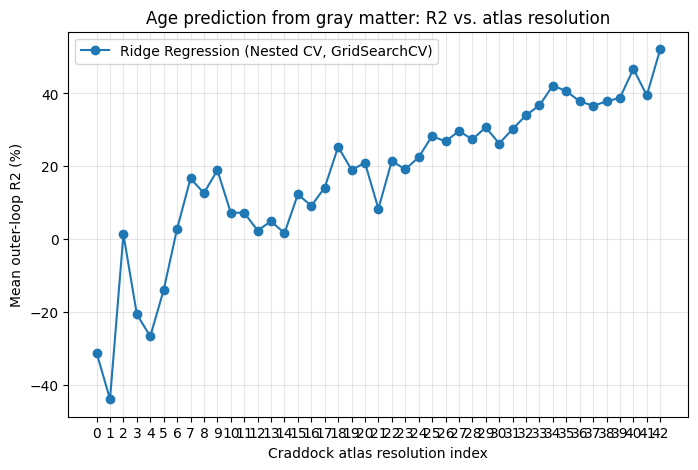

: 

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(craddock_indices, accuracies_ridge_nested, marker='o', color='tab:blue', label='Ridge Regression (Nested CV, GridSearchCV)')
plt.xlabel('Craddock atlas resolution index')
plt.ylabel('Mean outer-loop R2 (%)')
plt.title('Age prediction from gray matter: R2 vs. atlas resolution')
plt.xticks(craddock_indices)
plt.legend()
plt.grid(alpha=0.3)
plt.show()